# 02 · Results

Turns the outputs of `train_classical.py` and `train_roberta.py` into the report's
tables and figures. RoBERTa results use the learning rate chosen on validation AUROC.
All numbers are means over seeds 42–44 (± standard deviation).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()) / "src"))
from report_utils import *

ROOT = project_root()
RES, DATA = ROOT / "results", ROOT / "data" / "processed"
FIG, TAB = output_dirs(ROOT)
set_style()

res, BEST_LR = load_results(RES)
overall = res[res["attack"] == "all"]
print("RoBERTa learning rate chosen on validation:", BEST_LR)
print("Runs per detector and augmentation level:")
print(overall.groupby(["detector", "aug"])["seed"].nunique().unstack())

RoBERTa learning rate chosen on validation: 2e-05
Runs per detector and augmentation level:
aug                 0.00  0.25  0.50
detector                            
Baseline             3.0   NaN   NaN
RoBERTa              3.0   NaN   3.0
TF-IDF (word)        3.0   3.0   3.0
TF-IDF (word+char)   3.0   3.0   3.0


## 1. Main comparison (no augmentation)

In [2]:
def condition_table(metric, aug=0.0):
    s = summarise(overall[overall["aug"] == aug], ["detector", "condition_name"], metric)
    t = s.apply(lambda r: pm(r["mean"], r["std"]), axis=1).unstack()
    t = t.reindex(index=DETECTOR_ORDER, columns=CONDITION_ORDER)
    t.index.name, t.columns.name = "Detector", None
    return t

main_tpr = save_table(condition_table("tpr_at_5fpr"), "main_tpr", TAB,
                      "TPR (%) at 5% FPR by test condition, no augmentation (mean ± std over 3 seeds)")
main_tpr

saved tables/main_tpr.csv and .tex


,Seen gen.,Held-out gen.,Rep. penalty,Seen attacks,Held-out attacks
Detector,,,,,
Baseline,33.3 ± 0.0,22.1 ± 0.0,2.3 ± 0.0,33.6 ± 0.0,32.5 ± 0.0
TF-IDF (word),78.5 ± 0.0,83.6 ± 0.0,43.9 ± 0.0,75.3 ± 0.0,83.5 ± 0.0
TF-IDF (word+char),82.1 ± 0.0,85.1 ± 0.0,49.6 ± 0.0,79.2 ± 0.0,88.6 ± 0.0
RoBERTa,99.5 ± 0.0,98.0 ± 0.5,90.5 ± 0.9,96.2 ± 0.6,95.0 ± 1.5


In [3]:
main_auroc = save_table(condition_table("auroc"), "main_auroc", TAB,
                        "AUROC (×100) by test condition, no augmentation")
main_auroc

saved tables/main_auroc.csv and .tex


,Seen gen.,Held-out gen.,Rep. penalty,Seen attacks,Held-out attacks
Detector,,,,,
Baseline,76.6 ± 0.0,67.5 ± 0.0,23.4 ± 0.0,75.4 ± 0.0,76.8 ± 0.0
TF-IDF (word),95.0 ± 0.0,95.8 ± 0.0,70.4 ± 0.0,93.6 ± 0.0,80.0 ± 0.0
TF-IDF (word+char),96.1 ± 0.0,96.5 ± 0.0,73.7 ± 0.0,94.6 ± 0.0,82.5 ± 0.0
RoBERTa,99.9 ± 0.0,99.5 ± 0.1,96.0 ± 0.4,98.4 ± 0.1,88.9 ± 0.5


In [4]:
main_fpr = save_table(condition_table("fpr_observed"), "main_fpr", TAB,
                      "Observed FPR (%) on human test texts at the validation threshold")
main_fpr

saved tables/main_fpr.csv and .tex


,Seen gen.,Held-out gen.,Rep. penalty,Seen attacks,Held-out attacks
Detector,,,,,
Baseline,4.7 ± 0.0,4.7 ± 0.0,4.7 ± 0.0,5.5 ± 0.0,4.4 ± 0.0
TF-IDF (word),4.4 ± 0.0,4.4 ± 0.0,4.4 ± 0.0,5.5 ± 0.0,35.8 ± 0.0
TF-IDF (word+char),5.1 ± 0.0,5.1 ± 0.0,5.1 ± 0.0,6.3 ± 0.0,38.0 ± 0.0
RoBERTa,4.3 ± 0.6,4.3 ± 0.6,4.3 ± 0.6,7.4 ± 0.1,39.8 ± 2.1


## 2. Generalisation gaps and hypotheses
Gap = TPR on seen generators minus TPR on the other condition (percentage points).
The error ratio compares missed AI texts: (1 − TPR held-out) / (1 − TPR seen).

In [5]:
m = (overall[overall["aug"] == 0].groupby(["detector", "condition"])["tpr_at_5fpr"]
     .mean().unstack())
gaps = pd.DataFrame({
    "Seen": m["test_seen"] * 100,
    "Held-out gen.": m["test_unseen"] * 100,
    "Gap held-out (pp)": (m["test_seen"] - m["test_unseen"]) * 100,
    "Missed-AI ratio held-out": (1 - m["test_unseen"]) / (1 - m["test_seen"]),
    "Gap rep. penalty (pp)": (m["test_seen"] - m["test_reppen"]) * 100,
}).reindex(DETECTOR_ORDER).round(2).rename_axis("Detector")
save_table(gaps, "generalisation_gaps", TAB, "Generalisation gaps relative to seen generators (no augmentation)")
gaps

saved tables/generalisation_gaps.csv and .tex


,Seen,Held-out gen.,Gap held-out (pp),Missed-AI ratio held-out,Gap rep. penalty (pp)
Detector,,,,,
Baseline,33.30,22.13,11.17,1.17,30.96
TF-IDF (word),78.51,83.60,-5.08,0.76,34.65
TF-IDF (word+char),82.10,85.14,-3.04,0.83,32.55
RoBERTa,99.45,97.96,1.50,3.73,8.99


In [6]:
g = gaps["Gap held-out (pp)"]
print(f"H1  RoBERTa lower TPR on held-out than seen generators: {g['RoBERTa'] > 0} "
      f"(gap {g['RoBERTa']:.2f} pp)")
print(f"H2  TF-IDF (word+char) drop larger than RoBERTa drop: {g['TF-IDF (word+char)'] > g['RoBERTa']} "
      f"(TF-IDF {g['TF-IDF (word+char)']:.2f} pp vs RoBERTa {g['RoBERTa']:.2f} pp)")

H1  RoBERTa lower TPR on held-out than seen generators: True (gap 1.50 pp)
H2  TF-IDF (word+char) drop larger than RoBERTa drop: False (TF-IDF -3.04 pp vs RoBERTa 1.50 pp)


## 3. Per-generator detection rate (seed 42, no augmentation)
Separates the effect of *being unseen* from the effect of *generator type* (base vs chat).

In [7]:
rows = []
for key in ["tfidf_word_char", "roberta-base"]:
    for cond in ["test_seen", "test_unseen"]:
        p = load_predictions(RES, DATA, key, cond, lr=BEST_LR if key == "roberta-base" else None)
        ai = p[p["label"] == 1].groupby("model")["pred"].mean()
        for gen, tpr in ai.items():
            rows.append({"detector": DETECTOR_NAMES[key], "generator": gen, "tpr": tpr})
pg = pd.DataFrame(rows).pivot(index="generator", columns="detector", values="tpr") * 100
pg.insert(0, "Split", ["held-out" if g in HELDOUT_GENERATORS else "seen" for g in pg.index])
pg.insert(1, "Type", pg.index.map(GENERATOR_TYPE))
pg = pg.sort_values(["Split", "Type"], ascending=[False, True]).round(1)
save_table(pg, "per_generator", TAB, "Detection rate (%) per generator at 5% FPR, seed 42, no augmentation")
pg

saved tables/per_generator.csv and .tex


detector,Split,Type,RoBERTa,TF-IDF (word+char)
generator,,,,
cohere,seen,base,98.9,64.8
gpt2,seen,base,99.6,81.5
gpt3,seen,base,100.0,83.4
mistral,seen,base,98.3,68.5
chatgpt,seen,chat,100.0,96.9
cohere-chat,seen,chat,99.0,81.0
mistral-chat,seen,chat,100.0,97.1
mpt,held-out,base,91.1,68.3
gpt4,held-out,chat,100.0,80.7


saved figures/per_generator.pdf and .png


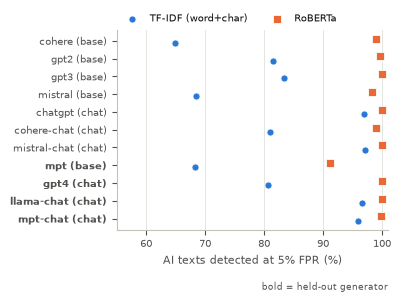

In [8]:
fig, ax = plt.subplots(figsize=(COL_W, 2.6))
order = pg.index.tolist()[::-1]
y = np.arange(len(order))
for det, dy in [("TF-IDF (word+char)", -0.12), ("RoBERTa", 0.12)]:
    ax.scatter(pg.loc[order, det], y + dy, s=26, marker=MARKERS[det], color=COLORS[det],
               edgecolor="#fcfcfb", linewidth=0.6, label=det, zorder=3)
labels = [f"{g} ({pg.loc[g, 'Type']})" for g in order]
ax.set_yticks(y, labels)
for tick, g in zip(ax.get_yticklabels(), order):
    if g in HELDOUT_GENERATORS:
        tick.set_fontweight("bold")
ax.set_xlabel("AI texts detected at 5% FPR (%)")
ax.grid(axis="y", visible=False)
ax.set_xlim(left=min(55, pg[["TF-IDF (word+char)", "RoBERTa"]].min().min() - 5), right=101)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
ax.text(1.0, -0.3, "bold = held-out generator", transform=ax.transAxes,
        ha="right", fontsize=6.5, color=INK2)
save_fig(fig, "per_generator", FIG)
plt.show()

## 4. Robustness to attacks (no augmentation)

In [9]:
atk = res[(res["attack"] != "all") & (res["aug"] == 0)
          & res["model"].isin(["tfidf_word_char", "roberta-base"])]
s = atk.groupby(["attack", "detector"])[["tpr_at_5fpr", "fpr_observed", "auroc"]].mean().unstack()
per_attack = pd.DataFrame({
    (det, met): (s[(col, det)] * 100).round(1)
    for det in ["TF-IDF (word+char)", "RoBERTa"]
    for met, col in [("TPR", "tpr_at_5fpr"), ("FPR", "fpr_observed"), ("AUROC", "auroc")]
})
per_attack.columns = [f"{d} {m}" for d, m in per_attack.columns]
per_attack.insert(0, "In training aug.", ["yes" if a in SEEN_ATTACKS else "no" for a in per_attack.index])
per_attack = per_attack.reindex(SEEN_ATTACKS + HELDOUT_ATTACKS)
save_table(per_attack, "per_attack", TAB,
           "Per-attack TPR, FPR and AUROC (%), no augmentation; FPR is measured on attacked human texts")
per_attack

saved tables/per_attack.csv and .tex


,In training aug.,TF-IDF (word+char) TPR,TF-IDF (word+char) FPR,TF-IDF (word+char) AUROC,RoBERTa TPR,RoBERTa FPR,RoBERTa AUROC
attack,,,,,,,
article_deletion,yes,80.4,4.2,96.0,99.0,1.3,99.8
number,yes,82.3,5.1,96.1,99.4,4.0,99.9
paraphrase,yes,73.6,13.7,87.4,81.5,32.5,77.9
synonym,yes,75.8,4.8,94.5,99.0,1.9,99.8
perplexity_misspelling,yes,82.2,5.0,96.1,98.9,2.2,99.8
alternative_spelling,yes,81.2,4.8,96.0,99.4,2.7,99.8
homoglyph,no,96.5,74.8,81.6,82.3,10.0,94.3
zero_width_space,no,100.0,100.0,50.0,94.9,89.2,68.5
whitespace,no,82.1,5.1,96.1,98.8,1.2,99.8


saved figures/per_attack.pdf and .png


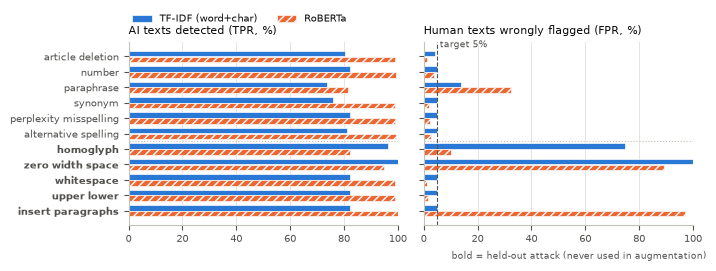

In [10]:
attacks = SEEN_ATTACKS + HELDOUT_ATTACKS
y = np.arange(len(attacks))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 2.6), sharey=True)
for ax, metric, title in [(axes[0], "TPR", "AI texts detected (TPR, %)"),
                          (axes[1], "FPR", "Human texts wrongly flagged (FPR, %)")]:
    for det, dy in [("TF-IDF (word+char)", 0.19), ("RoBERTa", -0.19)]:
        ax.barh(y + dy, per_attack.loc[attacks, f"{det} {metric}"], height=0.36,
                color=COLORS[det], hatch=HATCH.get(det), edgecolor="#fcfcfb",
                linewidth=0.5, label=det)
    ax.set_title(title, loc="left", color=INK)
    ax.set_xlim(0, 100)
    ax.grid(axis="y", visible=False)
    ax.axhline(len(HELDOUT_ATTACKS) - 0.5, color=AXIS, linewidth=0.8, linestyle=":")
axes[1].axvline(5, color=INK2, linewidth=0.8, linestyle="--")
axes[1].text(6, y[0] + 0.45, "target 5%", fontsize=6.5, color=INK2, va="bottom")
axes[0].set_yticks(y, [a.replace("_", " ") for a in attacks])
for tick, a in zip(axes[0].get_yticklabels(), attacks):
    if a in HELDOUT_ATTACKS:
        tick.set_fontweight("bold")
fig.text(0.99, -0.01, "bold = held-out attack (never used in augmentation)",
         ha="right", fontsize=6.5, color=INK2)
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, borderaxespad=0)
fig.tight_layout()
save_fig(fig, "per_attack", FIG)
plt.show()

## 5. Effect of adversarial augmentation
AUROC is threshold-free, so it shows the change in separability without the
threshold shifts between runs.

In [11]:
aug_rows = overall[overall["model"].isin(["tfidf_word_char", "roberta-base"])
                  & overall["condition"].isin(["test_seen", "test_seen_attacks", "test_heldout_attacks"])]
a = aug_rows.groupby(["detector", "aug", "condition_name"])[["tpr_at_5fpr", "fpr_observed", "auroc"]].agg(["mean", "std"])
aug_table = pd.DataFrame({
    f"{cond} {name}": a.xs(cond, level="condition_name").apply(
        lambda r: pm(r[(col, "mean")], r[(col, "std")]), axis=1)
    for cond in ["Seen gen.", "Seen attacks", "Held-out attacks"]
    for name, col in [("TPR", "tpr_at_5fpr"), ("AUROC", "auroc")]
})
save_table(aug_table, "augmentation", TAB, "Effect of the augmentation proportion (TPR and AUROC, %)")
aug_table

saved tables/augmentation.csv and .tex


Seen gen. TPR Seen gen. AUROC Seen attacks TPR  \
detector           aug                                                   
RoBERTa            0.00    99.5 ± 0.0      99.9 ± 0.0       96.2 ± 0.6   
                   0.50    99.4 ± 0.2      99.9 ± 0.0       98.4 ± 0.2   
TF-IDF (word+char) 0.00    82.1 ± 0.0      96.1 ± 0.0       79.2 ± 0.0   
                   0.25    81.7 ± 0.2      96.0 ± 0.0       79.3 ± 0.0   
                   0.50    81.6 ± 0.1      95.8 ± 0.0       79.4 ± 0.2   

                        Seen attacks AUROC Held-out attacks TPR  \
detector           aug                                            
RoBERTa            0.00         98.4 ± 0.1           95.0 ± 1.5   
                   0.50         99.4 ± 0.0           91.4 ± 1.6   
TF-IDF (word+char) 0.00         94.6 ± 0.0           88.6 ± 0.0   
                   0.25         94.6 ± 0.0           88.2 ± 0.1   
                   0.50         94.5 ± 0.0           88.1 ± 0.3   

                        Held-out attacks AUROC  
detector           aug                          
RoBERTa            0.00             88.9 ± 0.5  
                   0.50             88.2 ± 1.5  
TF-IDF (word+char) 0.00             82.5 ± 0.0  
                   0.25             82.3 ± 0.1  
                   0.50             82.0 ± 0.1

saved figures/augmentation.pdf and .png


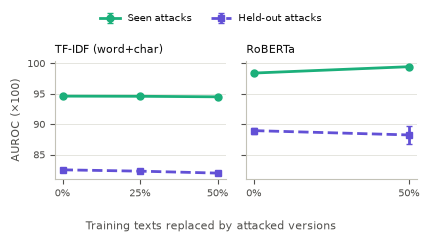

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(PAGE_W * 0.62, 2.3), sharey=True)
series = [("Seen attacks", PAIR[0], "o", "-"), ("Held-out attacks", PAIR[1], "s", "--")]
for ax, det in zip(axes, ["TF-IDF (word+char)", "RoBERTa"]):
    for cond, colour, marker, style in series:
        d = a.loc[det].xs(cond, level="condition_name")
        ax.errorbar(d.index, d[("auroc", "mean")] * 100, yerr=d[("auroc", "std")].fillna(0) * 100,
                    color=colour, marker=marker, linestyle=style, capsize=2, label=cond)
    ax.set_title(det, loc="left", color=INK)
    ax.set_xticks(sorted(d.index), [f"{int(x * 100)}%" for x in sorted(d.index)])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("AUROC (×100)")
fig.supxlabel("Training texts replaced by attacked versions", fontsize=8, color=INK2)
handles, labels = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save_fig(fig, "augmentation", FIG)
plt.show()

In [13]:
pa = res[(res["attack"] != "all") & res["model"].isin(["tfidf_word_char", "roberta-base"])
         & res["aug"].isin([0.0, 0.5])]
pa = pa.groupby(["attack", "detector", "aug"])[["tpr_at_5fpr", "fpr_observed", "auroc"]].mean()
pa = (pa * 100).round(1).unstack(["detector", "aug"])
pa.columns = [f"{d} {m.split('_')[0].upper()} aug{int(g * 100)}" for m, d, g in pa.columns]
pa = pa.reindex(SEEN_ATTACKS + HELDOUT_ATTACKS)
pa = pa[sorted(pa.columns, key=lambda c: (not c.startswith("TF"), c))]
save_table(pa, "augmentation_per_attack", TAB, "Per-attack results with 0% and 50% augmentation (%)")
pa

saved tables/augmentation_per_attack.csv and .tex


,TF-IDF (word+char) AUROC aug0,TF-IDF (word+char) AUROC aug50,TF-IDF (word+char) FPR aug0,TF-IDF (word+char) FPR aug50,TF-IDF (word+char) TPR aug0,TF-IDF (word+char) TPR aug50,RoBERTa AUROC aug0,RoBERTa AUROC aug50,RoBERTa FPR aug0,RoBERTa FPR aug50,RoBERTa TPR aug0,RoBERTa TPR aug50
attack,,,,,,,,,,,,
article_deletion,96.0,95.7,4.2,4.6,80.4,80.3,99.8,99.9,1.3,1.4,99.0,99.0
number,96.1,95.7,5.1,5.4,82.3,81.7,99.9,99.9,4.0,3.7,99.4,99.3
paraphrase,87.4,88.4,13.7,12.4,73.6,74.4,77.9,92.7,32.5,41.3,81.5,95.3
synonym,94.5,94.5,4.8,5.3,75.8,77.5,99.8,99.8,1.9,1.5,99.0,98.7
perplexity_misspelling,96.1,95.8,5.0,5.3,82.2,81.5,99.8,99.8,2.2,2.5,98.9,98.8
alternative_spelling,96.0,95.7,4.8,5.0,81.2,81.0,99.8,99.9,2.7,3.1,99.4,99.2
homoglyph,81.6,80.8,74.8,75.6,96.5,95.7,94.3,95.5,10.0,1.9,82.3,77.5
zero_width_space,50.0,50.0,100.0,100.0,100.0,100.0,68.5,67.6,89.2,67.2,94.9,82.8
whitespace,96.1,95.8,5.1,5.4,82.1,81.6,99.8,99.8,1.2,0.6,98.8,97.8


## 6. Computational efficiency

In [14]:
import json
ce = pd.read_csv(RES / "classical_efficiency.csv")
re_ = pd.read_csv(RES / "roberta_efficiency.csv")
re_ = re_[np.isclose(re_["lr"], BEST_LR)]
hw_c = json.loads((RES / "hardware_classical.json").read_text())
hw_r = json.loads((RES / "hardware_roberta.json").read_text())

def eff_row(df, key, size_col, hardware):
    d = df[(df["model"] == key) & (df["aug"] == 0)]
    return {"Detector": DETECTOR_NAMES[key], "Hardware": hardware,
            "Train time (s)": round(d["train_time_s"].mean(), 1),
            "Inference (texts/s)": round(d["infer_texts_per_s"].mean()),
            "Size (MB)": round(d["model_size_mb"].mean(), 2),
            "Parameters / features": f"{int(d[size_col].mean()):,}"}

cpu = f"{hw_c.get('machine', '')} CPU ({hw_c.get('cpu_count', '?')} cores)"
gpu = hw_r.get("gpu") or hw_r.get("device", "GPU")
efficiency = pd.DataFrame(
    [eff_row(ce, k, "n_features", cpu) for k in ["baseline", "tfidf_word", "tfidf_word_char"]]
    + [eff_row(re_, "roberta-base", "n_params", gpu)]).set_index("Detector")
save_table(efficiency, "efficiency", TAB, "Training time, inference throughput and model size")
efficiency

saved tables/efficiency.csv and .tex


,Hardware,Train time (s),Inference (texts/s),Size (MB),Parameters / features
Detector,,,,,
Baseline,arm64 CPU (10 cores),0.3,64257,0.00,2
TF-IDF (word),arm64 CPU (10 cores),4.5,8621,31.89,"200,000"
TF-IDF (word+char),arm64 CPU (10 cores),18.0,1618,45.94,"400,000"
RoBERTa,Tesla T4,1087.7,185,498.59,"124,647,170"


## 7. Tuning and stability

In [15]:
eff_all = pd.read_csv(RES / "roberta_efficiency.csv")
tuning = (eff_all[(eff_all["aug"] == 0) & (eff_all["seed"] == 42)]
          [["lr", "best_epoch", "val_auroc"]].sort_values("lr").set_index("lr"))
tuning["val_auroc"] = (tuning["val_auroc"] * 100).round(2)
tuning["selected"] = np.where(np.isclose(tuning.index, BEST_LR), "yes", "")
save_table(tuning, "lr_tuning", TAB, "RoBERTa learning-rate selection on validation AUROC (seed 42)")
tuning

saved tables/lr_tuning.csv and .tex


,best_epoch,val_auroc,selected
lr,,,
0.00001,2,99.76,
0.00002,2,99.79,yes
0.00003,2,99.78,


In [16]:
cl_c = (res[(res["model"] != "roberta-base") & (res["condition"] == "test_seen")]
        .groupby(["detector", "aug"])["C"].agg(lambda s: ", ".join(sorted({str(v) for v in s}))))
print("Logistic-regression C chosen on validation AUROC:")
print(cl_c.to_string())

Logistic-regression C chosen on validation AUROC:
detector            aug 
Baseline            0.00    10.0
TF-IDF (word)       0.00    10.0
                    0.25    10.0
                    0.50    10.0
TF-IDF (word+char)  0.00    10.0
                    0.25    10.0
                    0.50    10.0


In [17]:
thr = re_[["aug", "seed", "best_epoch", "threshold", "val_auroc"]].sort_values(["aug", "seed"])
thr = thr.round({"threshold": 4, "val_auroc": 4}).set_index(["aug", "seed"])
save_table(thr, "roberta_thresholds", TAB, "RoBERTa decision thresholds (5% validation FPR) per run")
thr

saved tables/roberta_thresholds.csv and .tex


best_epoch  threshold  val_auroc
aug seed                                  
0.0 42             2     0.9545     0.9979
    43             1     0.0040     0.9982
    44             2     0.3471     0.9980
0.5 42             2     0.9725     0.9979
    43             2     0.9891     0.9975
    44             2     0.9565     0.9983